# Stage 8: Jensen's alpha and performance evaluation

Stage 7 asked whether single stocks were mispriced. This stage asks the same of our **portfolios**: did
they earn more than their risk justified, and is that skill or luck?

**Jensen's alpha** is the portfolio's return above what the SML predicts for its beta:

α = r_p − [r_f + β_p (r_m − r_f)]

We estimate it by regression: r_p − r_f = α + β (r_m − r_f) + ε

The measures below answer slightly different questions:

| Measure | Formula | Question |
|---|---|---|
| **Sharpe** | Excess return / σ | Reward per unit of total risk? |
| **Treynor** | Excess return / β | Reward per unit of market risk? |
| **Jensen's alpha** | Regression intercept | Return above the SML? |
| **Information ratio** | α / residual σ | Alpha per unit of active risk? |
| **M²** | Sharpe × σ_m − market excess | Sharpe, in return units at market risk |
| **Sortino** | Excess return / downside deviation | Reward per unit of bad risk? |

All portfolios are the **walk-forward** versions, so each return was earned by a portfolio built only
from earlier data. Costs are excluded, and the holdout remains untouched.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pmo import backtest, models
from pmo import frontier as fr
from pmo import performance as perf
from pmo import returns as ret
from pmo.config import load_config
from pmo.pipeline import load
from pmo.plotting import FIGURES, INK, MUTED, SERIES_1, SERIES_2, SURFACE, apply_style

apply_style()
config = load_config()
data = load()
stocks = data.universe["symbol"].tolist()
market = config.market_proxy
HAIRCUT = config.survivorship_haircut
CAPPED, LONG_ONLY = fr.Constraints(upper=0.10), fr.Constraints()

excess = ret.select_period(data.excess, data.periods, "estimation")


def window_rate(frame):
    return data.risk_free["rf"].loc[frame.index].mean() * 12


def textbook(frame):
    return models.textbook_inputs(frame[stocks])


def practical(frame):
    premium = data.factors_long.loc[:frame.index.max(), "MKT_RF"].mean()
    return models.practical_inputs(frame[stocks], frame[market], premium)


def tangency(inputs, rule, haircut=0.0):
    def build(train):
        rate = window_rate(train)
        mean, cov = fr.annualize(*inputs(train), rate)
        return fr.solve_max_sharpe(mean - haircut, cov, rate, rule)
    return build


def lowest_risk(train):
    mean, cov = fr.annualize(*practical(train), window_rate(train))
    return fr.solve_min_variance(mean, cov, None, CAPPED)


FUND = "Fund (capped tangency)"
strategies = {
    FUND: tangency(practical, CAPPED, HAIRCUT),
    "Capped lowest risk": lowest_risk,
    "Long-only tangency": tangency(practical, LONG_ONLY, HAIRCUT),
    "Textbook capped tangency": tangency(textbook, CAPPED),
    "Equal weight": lambda train: pd.Series(1 / len(stocks), index=stocks),
    "Market tracker": lambda train: fr.tracking_portfolio(train[market], train[stocks]),
    "Market proxy": lambda train: pd.Series({market: 1.0}),
}
runs = {window: backtest.run(excess, strategies, window=window, step=12).returns
        for window in [60, 36]}
frame = runs[60]
index = frame["Market proxy"]
print(f"60-month window: {len(frame)} months from {frame.index.min():%b %Y} to {frame.index.max():%b %Y}")

60-month window: 93 months from Feb 2016 to Oct 2023


## 1. The scorecard against the Nifty

`Market tracker` is the long-only mix of our 25 stocks refitted each year to follow the Nifty most
closely. It uses no return forecasts at all.

In [2]:
portfolios = frame.drop(columns="Market proxy")
card = perf.scorecard(portfolios, index)
card.round(3)

,excess_return,volatility,beta,alpha,alpha_t,sharpe,treynor,residual_vol,information_ratio,m_squared,sortino,max_drawdown
Fund (capped tangency),0.145,0.164,0.866,0.065,2.529,0.884,0.168,0.076,0.854,0.056,1.494,-0.195
Capped lowest risk,0.113,0.140,0.679,0.049,1.983,0.805,0.166,0.081,0.615,0.043,1.497,-0.192
Long-only tangency,0.195,0.274,1.292,0.075,1.875,0.712,0.151,0.166,0.450,0.027,1.187,-0.390
Textbook capped tangency,0.141,0.164,0.868,0.060,2.351,0.857,0.162,0.075,0.803,0.051,1.457,-0.188
Equal weight,0.147,0.162,0.938,0.060,6.209,0.907,0.157,0.036,1.669,0.060,1.474,-0.254
Market tracker,0.119,0.164,0.943,0.031,2.979,0.727,0.126,0.039,0.796,0.030,1.163,-0.282


In [3]:
card_36 = perf.scorecard(runs[36].drop(columns="Market proxy"), runs[36]["Market proxy"])
print("36-month window")
card_36[["excess_return", "volatility", "beta", "alpha", "alpha_t", "sharpe", "information_ratio",
         "max_drawdown"]].round(3)

36-month window


,excess_return,volatility,beta,alpha,alpha_t,sharpe,information_ratio,max_drawdown
Fund (capped tangency),0.140,0.159,0.845,0.071,3.153,0.882,0.871,-0.192
Capped lowest risk,0.106,0.133,0.667,0.051,2.363,0.796,0.658,-0.169
Long-only tangency,0.158,0.186,0.818,0.092,2.381,0.849,0.695,-0.185
Textbook capped tangency,0.133,0.151,0.799,0.068,2.948,0.882,0.864,-0.166
Equal weight,0.141,0.156,0.943,0.064,7.498,0.904,1.826,-0.254
Market tracker,0.124,0.163,0.971,0.045,4.726,0.766,1.025,-0.276


On this table the fund looks like a success: positive alpha, a t-statistic above 2, and a good
information ratio. That reading is **wrong**, as the rest of this stage shows.

The first warning is the tracker. It was built only to copy the index, and it uses no return
forecasts, yet it also shows positive alpha with a high t-statistic. These are out-of-sample figures
from 2016 onward, after the proxy's dividend problem, so most of that gap is survivorship. It is also
a useful check: the tracker's alpha is close to the 3-point haircut chosen in Stage 6.

## 2. Alpha against a fair benchmark

The Nifty is an unfair benchmark, because it contained stocks that later failed and ours did not. The
tracker has the same survivorship as our portfolios, so alpha against it is much closer to the truth.

In [4]:
tracker = frame["Market tracker"]
others = frame.drop(columns=["Market proxy", "Market tracker"])
fair = perf.scorecard(others, tracker)[["beta", "alpha", "alpha_t", "information_ratio"]]
bounds = {name: perf.alpha_interval(others[name], tracker) for name in others}
fair["alpha_low"] = [bounds[name][0] for name in fair.index]
fair["alpha_high"] = [bounds[name][1] for name in fair.index]
fair["years_to_prove"] = (2 / fair["information_ratio"]) ** 2
fair.round(3)

,beta,alpha,alpha_t,information_ratio,alpha_low,alpha_high,years_to_prove
Fund (capped tangency),0.852,0.044,1.522,0.504,-0.013,0.097,15.746
Capped lowest risk,0.717,0.027,1.151,0.358,-0.020,0.076,31.159
Long-only tangency,1.249,0.046,0.962,0.253,-0.043,0.126,62.302
Textbook capped tangency,0.856,0.039,1.363,0.454,-0.015,0.093,19.377
Equal weight,0.969,0.032,3.073,0.964,0.010,0.049,4.308


`alpha_low` and `alpha_high` are 95% block-bootstrap ranges. `years_to_prove` is how long a track
record at this information ratio takes to reach a t-statistic of 2. The fund's range includes zero, so
we can't claim its alpha is real.

## 3. What does the alpha consist of?

A four-factor regression shows which style exposures sit behind the returns. Nifty excess returns
replace IIMA's market factor, as in Stage 2.

In [5]:
factors = data.factors.loc[frame.index].assign(MKT_RF=index)
fit = models.fit_factor_model(portfolios, factors)
exposures = fit.betas.copy()
exposures.insert(0, "alpha", fit.alpha * 12)
exposures.insert(1, "alpha_t", fit.alpha_t)
exposures["r_squared"] = fit.r_squared
exposures.round(3)

,alpha,alpha_t,SMB,HML,WML,MKT_RF,r_squared
Fund (capped tangency),0.075,3.380,0.078,-0.200,0.036,0.946,0.826
Capped lowest risk,0.058,2.078,-0.009,-0.136,0.003,0.742,0.693
Long-only tangency,0.116,2.666,0.157,-0.156,-0.154,1.261,0.647
Textbook capped tangency,0.068,3.045,0.058,-0.183,0.038,0.947,0.825
Equal weight,0.059,5.084,0.016,0.051,-0.011,0.907,0.955
Market tracker,0.037,3.546,-0.025,0.054,-0.060,0.904,0.949


The negative HML loading shows that the optimized portfolios lean toward expensive, quality-style
stocks. Style factors don't remove the alpha, which fits survivorship: they can't explain it, because
those factors are built from all stocks, including the ones that failed.

## 4. Skill or luck?

This is the sharpest test. **What would chance alone have produced?** We draw 2,000 random portfolios
from the same 25 stocks, each holding 12 at equal weight and redrawn every year. They use no
information, but they have the same survivorship and cover the same months. If the fund has skill, it
should beat most of them.

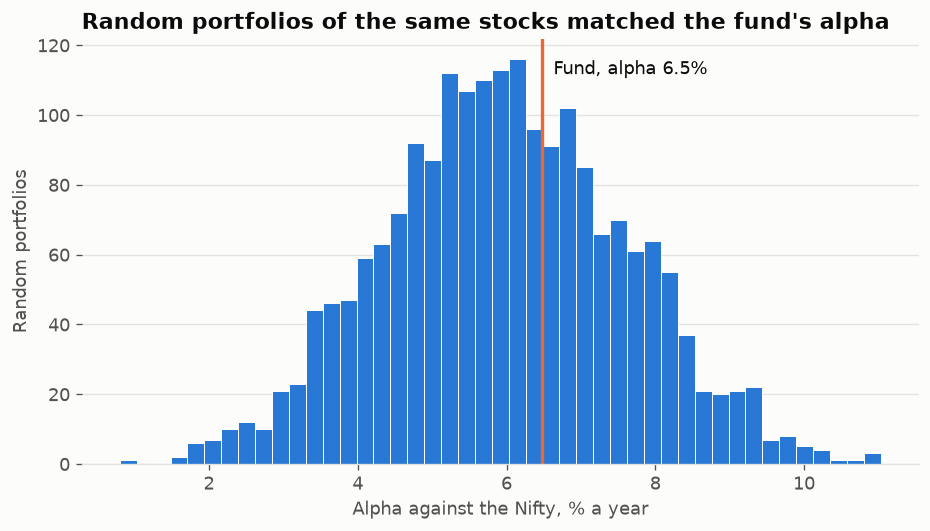

alpha  alpha_percentile  sharpe  \
60-month window Fund (capped tangency)    0.065             0.625   0.884   
                Capped lowest risk        0.049             0.268   0.805   
                Textbook capped tangency  0.060             0.520   0.857   
                Equal weight              0.060             0.509   0.907   
36-month window Fund (capped tangency)    0.071             0.668   0.882   
                Capped lowest risk        0.051             0.191   0.796   
                Textbook capped tangency  0.068             0.580   0.882   
                Equal weight              0.064             0.482   0.904   

                                          sharpe_percentile  \
60-month window Fund (capped tangency)                0.554   
                Capped lowest risk                    0.266   
                Textbook capped tangency              0.458   
                Equal weight                          0.662   
36-month window Fund (capped tangency)                0.558   
                Capped lowest risk                    0.232   
                Textbook capped tangency              0.560   
                Equal weight                          0.659   

                                          random_median_alpha  \
60-month window Fund (capped tangency)                  0.059   
                Capped lowest risk                      0.059   
                Textbook capped tangency                0.059   
                Equal weight                            0.059   
36-month window Fund (capped tangency)                  0.065   
                Capped lowest risk                      0.065   
                Textbook capped tangency                0.065   
                Equal weight                            0.065   

                                          random_median_sharpe  
60-month window Fund (capped tangency)                   0.868  
                Capped lowest risk                       0.868  
                Textbook capped tangency                 0.868  
                Equal weight                             0.868  
36-month window Fund (capped tangency)                   0.866  
                Capped lowest risk                       0.866  
                Textbook capped tangency                 0.866  
                Equal weight                             0.866

In [6]:
def random_scores(window, returns):
    random = perf.random_portfolios(excess[stocks], holdings=12, start=window)
    benchmark = returns["Market proxy"]
    betas = random.apply(lambda col: col.cov(benchmark) / benchmark.var())
    alpha = random.mean() * 12 - betas * benchmark.mean() * 12
    sharpe = random.mean() / random.std() * np.sqrt(12)
    return alpha, sharpe


rows = {}
scores = {}
for window, returns in runs.items():
    alpha, sharpe = random_scores(window, returns)
    scores[window] = alpha
    benchmark = returns["Market proxy"]
    card_w = perf.scorecard(returns.drop(columns="Market proxy"), benchmark)
    for name in [FUND, "Capped lowest risk", "Textbook capped tangency", "Equal weight"]:
        rows[f"{window}-month window", name] = {
            "alpha": card_w.loc[name, "alpha"], "alpha_percentile": perf.percentile_rank(card_w.loc[name, "alpha"], alpha),
            "sharpe": card_w.loc[name, "sharpe"], "sharpe_percentile": perf.percentile_rank(card_w.loc[name, "sharpe"], sharpe),
            "random_median_alpha": alpha.median(), "random_median_sharpe": sharpe.median()}

alpha = scores[60]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.hist(alpha * 100, bins=45, color=SERIES_1, edgecolor=SURFACE, linewidth=0.6)
fund_alpha = card.loc[FUND, "alpha"] * 100
ax.axvline(fund_alpha, color=SERIES_2, linewidth=2)
ax.annotate(f"Fund, alpha {fund_alpha:.1f}%", (fund_alpha, ax.get_ylim()[1] * 0.95), xytext=(7, 0),
            textcoords="offset points", color=INK, va="top")
ax.set_xlabel("Alpha against the Nifty, % a year")
ax.set_ylabel("Random portfolios")
ax.set_title("Random portfolios of the same stocks matched the fund's alpha")
fig.savefig(FIGURES / "08_random_portfolios.png")
plt.show()
pd.DataFrame(rows).T.round(3)

**This settles it for the estimation period.** The fund's alpha is unremarkable next to portfolios
chosen by chance from the same stocks. Its t-statistic against the Nifty mostly measures the bias in
the universe.

### Did optimization at least reduce risk?

Return isn't the only thing an optimizer can improve. This compares realized risk with the same random
portfolios. For these measures a **low** percentile is good.

In [7]:
rows = {}
for window, returns in runs.items():
    random = perf.random_portfolios(excess[stocks], holdings=12, start=window)
    volatility = random.std() * np.sqrt(12)
    drawdown = -random.apply(perf.stats.max_drawdown)
    for name in [FUND, "Capped lowest risk", "Equal weight", "Market proxy"]:
        rows[f"{window}-month window", name] = {
            "volatility": returns[name].std() * np.sqrt(12),
            "volatility_percentile": perf.percentile_rank(returns[name].std() * np.sqrt(12), volatility),
            "worst_drawdown": perf.stats.max_drawdown(returns[name]),
            "drawdown_percentile": perf.percentile_rank(-perf.stats.max_drawdown(returns[name]), drawdown),
            "random_median_volatility": volatility.median(),
            "random_median_drawdown": -drawdown.median()}
risk_check = pd.DataFrame(rows).T
risk_check.round(3)

volatility  volatility_percentile  \
60-month window Fund (capped tangency)       0.164                  0.300   
                Capped lowest risk           0.140                  0.000   
                Equal weight                 0.162                  0.208   
                Market proxy                 0.169                  0.468   
36-month window Fund (capped tangency)       0.159                  0.286   
                Capped lowest risk           0.133                  0.000   
                Equal weight                 0.156                  0.160   
                Market proxy                 0.161                  0.394   

                                        worst_drawdown  drawdown_percentile  \
60-month window Fund (capped tangency)          -0.195                0.020   
                Capped lowest risk              -0.192                0.016   
                Equal weight                    -0.254                0.316   
                Market proxy                    -0.313                0.862   
36-month window Fund (capped tangency)          -0.192                0.006   
                Capped lowest risk              -0.169                0.000   
                Equal weight                    -0.254                0.314   
                Market proxy                    -0.313                0.869   

                                        random_median_volatility  \
60-month window Fund (capped tangency)                     0.169   
                Capped lowest risk                         0.169   
                Equal weight                               0.169   
                Market proxy                               0.169   
36-month window Fund (capped tangency)                     0.163   
                Capped lowest risk                         0.163   
                Equal weight                               0.163   
                Market proxy                               0.163   

                                        random_median_drawdown  
60-month window Fund (capped tangency)                  -0.272  
                Capped lowest risk                      -0.272  
                Equal weight                            -0.272  
                Market proxy                            -0.272  
36-month window Fund (capped tangency)                  -0.270  
                Capped lowest risk                      -0.270  
                Equal weight                            -0.270  
                Market proxy                            -0.270

## 5. Is alpha stable over time?

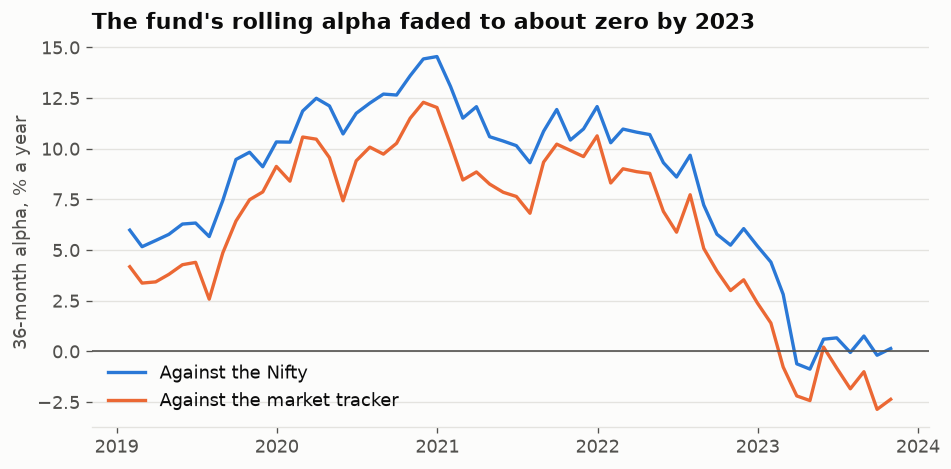

,Against the Nifty,Against the tracker
min,-0.9,-2.9
50%,9.7,7.6
max,14.5,12.3


In [8]:
rolling_index = perf.rolling_alpha(frame[FUND], index) * 100
rolling_fair = perf.rolling_alpha(frame[FUND], tracker) * 100
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(rolling_index.index, rolling_index, color=SERIES_1, label="Against the Nifty")
ax.plot(rolling_fair.index, rolling_fair, color=SERIES_2, label="Against the market tracker")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_ylabel("36-month alpha, % a year")
ax.set_title("The fund's rolling alpha faded to about zero by 2023")
ax.legend(frameon=False, loc="lower left")
fig.savefig(FIGURES / "08_rolling_alpha.png")
plt.show()
pd.DataFrame({"Against the Nifty": rolling_index.describe()[["min", "50%", "max"]],
              "Against the tracker": rolling_fair.describe()[["min", "50%", "max"]]}).round(1)

## Stage 8 conclusions

1. **The fund's alpha against the Nifty looks significant, but it isn't skill:** the choice of stocks
   produced most of it.
2. **Even a pure index copy showed alpha:** the tracker's out-of-sample gap supports the 3-point
   survivorship haircut from Stage 6 with a separate measurement.
3. **Against a fair benchmark, alpha isn't significant:** the 95% range includes zero, and proving
   it would take over a decade of data.
4. **Random portfolios kept up:** the fund landed near the middle of 2,000 random portfolios.
5. **Drawdown control is the real contribution:** the fund's worst loss ranks among the smallest of
   the random portfolios, and the lowest-risk version beat all of them on volatility. There is
   evidence that optimization controlled risk, and none that it picked winners.
6. **Alpha faded:** the fund's rolling three-year alpha fell to about zero by 2023, and slightly below
   zero against the tracker.

### What this means for the final tool

The tool should not advertise past alpha or outperformance against the Nifty. It can fairly present
the portfolio as a diversified, risk-controlled way to hold these stocks. Stage 10 gives the final
evidence on the holdout, but every result here depends on a universe of survivors.